# Examples of high, low and typical normalising ratios per pair (2-fish, newest table)

**Normalising ratio** = $r_{norm} / u_{1,norm}$ = (max |v| of the recorded peak pattern) / (max |v| of fish 1's unit-current model),
on EODs where both maxima are on the **same pair** (`EOD_normalizing_factors_2fish_newest.ipynb`). Fish 1 is the emitter (ground
truth), fish 0 is silent. Run: `eod_assignment_control_groups.py --rec 2-fish` (ZEUS masks of the EOD's newest frame, BEM conductivities,
sink at the tail tip; recorded pattern at the sample where |V| peaks; model × −1).

**Picks, per pair and per set**: two sets, EODs that shape only assigned **correctly** (to fish 1) and **incorrectly** (to fish 0).
In each set and pair (EODs with both maxima on that pair): the 2 highest ratios, the 2 lowest, and the one closest to that set's
mean at that pair; picks of one kind at least 10 video frames apart, no EOD twice (a set with fewer than 5 EODs at a pair gives
fewer picks).

**Each figure**
- **tank**: ZEUS masks of the EOD's frame (fish 1 blue, fish 0 orange), electrodes (+ filled, − open), the deciding pair joined.
- **zooms** (one column per fish): top, the mask with its midline (head = dot) and electrodes inside the window; bottom, the same
  window of the raw video frame with the mask outline. Window side 1.6 × the fish's median midline length.
- **voltages**, per pair: left, **volts**: recorded (black) and each fish's model × (the deciding pair's **mean** ratio), so a
  typical EOD at that pair would match the recording in size; legend $\lVert r - \hat r\rVert/\max|r|$. Right, **shape**: each
  pattern scaled to max |v| = 1; legend shape L2 (the run's $d_f$).

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from scipy.spatial import cKDTree
from scipy.ndimage import binary_erosion
import eod_examples as ex                                            # frame_masks, fish_midlines, video_frame (sets the Agg backend)
%matplotlib inline

RES = 'results/eod_ground_truth'
SRC = f'{RES}/conductivities/normalizing_factors_newest'
OUT = f'{SRC}/ratio_examples'; os.makedirs(f'{OUT}/per_eod_by_set', exist_ok=True)
TRACK = 'data/2_fish_silent/elephantnose_2024-02-13T14-33-21_Shiv_tracking_final.pkl'
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_2-fish.csv')
FISH_COL = {0: '#F08A24', 1: '#1F5FBF'}; FISH_NAME = {0: 'fish 0 (silent)', 1: 'fish 1 (emitter)'}
PAIRS = range(1, 11); MIN_SEP = 10

with open(TRACK, 'rb') as f: trk = pickle.load(f)
C = dict(frames=trk['frames'], fish=(0, 1), P=trk['shape'][0], fps=trk['fps'], data='data/2_fish_silent', video='video2024-02-13T14_33_21.avi')
P = C['P']; PX_CM = P / 60
d = pd.read_csv(f'{RES}/conductivities/my_model_shape_synch_fix_newest.csv')
T = pd.read_csv(f'{SRC}/normalizing_factors_per_eod.csv')
assert (T.eod_row.to_numpy() == d.eod_row.to_numpy()).all()
R = d[[f'r_raw_p{p}' for p in PAIRS]].to_numpy()
U = {f: -d[[f'u{f}_raw_p{p}' for p in PAIRS]].to_numpy() for f in (0, 1)}       # model x -1 (as compared)
SEL = T[T['same pair (r, fish 1)'] & T['r_norm / u1_norm'].notna()]
MEAN = SEL.groupby('r pair')['r_norm / u1_norm'].mean()

def spread(idx, n):
    out = []
    for i in idx:
        if all(abs(T.Frame[i] - T.Frame[j]) >= MIN_SEP for j in out): out.append(i)
        if len(out) == n: break
    return out
picks = []
SETS = {'correct': SEL.correct, 'wrong': ~SEL.correct}
for set_, msk in SETS.items():
    for p in PAIRS:
        s = SEL[msk & (SEL['r pair'] == p)].sort_values('r_norm / u1_norm')
        if s.empty: continue
        v = s['r_norm / u1_norm']; vall = SEL.loc[SEL['r pair'] == p, 'r_norm / u1_norm']; used = set()
        for kind, idx in (('highest', spread(s.index[::-1], 2)), ('lowest', spread(s.index, 2)),
                          ('closest to mean', [(v - v.mean()).abs().idxmin()])):
            for i in idx:
                if i in used: continue
                used.add(i)
                picks.append(dict(set=set_, pair=p, kind=kind, i=i, ratio=T.loc[i, 'r_norm / u1_norm'], pair_mean=MEAN[p],
                                  set_mean=v.mean(), n_set=len(v), percentile=100 * (vall < T.loc[i, 'r_norm / u1_norm']).mean()))
PK = pd.DataFrame(picks)
PK = PK.join(T[['eod_row', 'Frame', 'clean good', 'correct', 'r_norm', 'u1_norm', 'u0_norm']], on='i')
med_len = {}

In [2]:
def gap_cm(m):
    if not (m[0].any() and m[1].any()): return np.nan
    e = [np.argwhere(mk & ~binary_erosion(mk)) for mk in m]
    return cKDTree(e[0]).query(e[1], k=1)[0].min() / PX_CM

def draw_electrodes(ax, pstar, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2); mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) == pstar
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def window(m, f):
    yy, xx = np.nonzero(m[f]); h = 0.8 * med_len[f]
    return xx.mean() - h, xx.mean() + h, yy.mean() - h, yy.mean() + h

def tank(ax, m, pstar):
    img = np.ones((P, P, 3))
    for f in (0, 1): img[m[f]] = to_rgb(FISH_COL[f])
    ax.imshow(img, extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for f in (0, 1):
        if m[f].any():
            yy, xx = np.nonzero(m[f]); ax.text(xx.mean() + 20, yy.mean() - 20, str(f), fontsize=11, color=FISH_COL[f], fontweight='bold')
    draw_electrodes(ax, pstar)
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f'tank (fish 1 blue, fish 0 orange; deciding pair {pstar} joined)', fontsize=9)

def zoom_mask(ax, m, mids, f, pstar):
    if not m[f].any(): ax.axis('off'); ax.text(0.5, 0.5, f'{FISH_NAME[f]}: no mask', ha='center', transform=ax.transAxes); return
    x0, x1, y0, y1 = window(m, f)
    img = np.ones((P, P, 3))
    for g in (0, 1): img[m[g]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    if mids[f] is not None:
        ml = mids[f] * (P - 1); ax.plot(ml[:, 1], ml[:, 0], color='#2b2b2b', lw=1); ax.plot(ml[-1, 1], ml[-1, 0], 'o', ms=3.5, color='#2b2b2b')
    draw_electrodes(ax, pstar, lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM; h2 = x1 - x0
    ax.add_patch(Rectangle((x1 - 0.06 * h2 - sb, y1 - 0.06 * h2), sb, 0.012 * h2, color='#2b2b2b'))
    ax.text(x1 - 0.06 * h2 - sb / 2, y1 - 0.075 * h2, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == 1 else 0.8)
    ax.set_title(f'{FISH_NAME[f]}: mask {m[f].sum()} px', fontsize=9, color=FISH_COL[f], fontweight='bold' if f == 1 else 'normal')

def zoom_video(ax, frame_img, m, f):
    if not m[f].any(): ax.axis('off'); return
    x0, x1, y0, y1 = window(m, f)
    ax.imshow(frame_img, cmap='gray', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for g in (0, 1):
        if m[g].any(): ax.contour(m[g].astype(float), levels=[0.5], colors=[FISH_COL[g]], linewidths=0.9)
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == 1 else 0.8)
    ax.set_title('raw video, mask outlines', fontsize=8.5, color='#5a5a55')

def voltages(axv, axs, i, pstar):
    r = R[i]; x = np.arange(1, 11); scale = MEAN[pstar]
    axv.plot(x, r, '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    axs.plot(x, r / np.abs(r).max(), '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    for f in (1, 0):
        u = U[f][i]
        if not np.isfinite(u).all(): continue
        kw = dict(color=FISH_COL[f], lw=2 if f == 1 else 1.2, ms=5 if f == 1 else 3.5, ls='-' if f == 1 else '--', marker='s')
        pv = scale * u
        axv.plot(x, pv, label=f'{FISH_NAME[f]}: {np.linalg.norm(r - pv) / np.abs(r).max():.2f}', **kw)
        axs.plot(x, u / np.abs(u).max(), label=f'{FISH_NAME[f]}: {d.loc[i, f"d{f}"]:.2f}', **kw)
    for ax, yl, tt in ((axv, 'recorded peak pattern (V)', f'volts: recorded vs model × pair-{pstar} mean ratio ({scale:.2f}); legend ‖r − r̂‖ / max|r|'),
                       (axs, 'scaled to max |v| = 1', 'shape: each pattern scaled to max |v| = 1; legend shape L2')):
        ax.axhline(0, color='#8a8a85', lw=0.8); ax.axvspan(pstar - 0.4, pstar + 0.4, color='#e6e6e3', zorder=0)
        ax.set(xticks=x, xlabel='electrode pair (grey band: deciding pair)', ylabel=yl); ax.set_title(tt, fontsize=9); ax.legend(fontsize=8, frameon=False)

def figure(row):
    i = int(row.i); k = int(row.Frame); pstar = int(row.pair)
    m = ex.frame_masks(C, k); mids = ex.fish_midlines(m); vid = ex.video_frame(C, k)
    fig = plt.figure(figsize=(17, 12.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], width_ratios=[1.35, 1, 1], hspace=0.16, wspace=0.04, top=0.94, bottom=0.05, left=0.04, right=0.99)
    tank(fig.add_subplot(gs[0, 0]), m, pstar)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for c_, f in enumerate((1, 0)):
        zoom_mask(fig.add_subplot(gz[0, c_]), m, mids, f, pstar); zoom_video(fig.add_subplot(gz[1, c_]), vid, m, f)
    gb = gs[1, :].subgridspec(1, 2, wspace=0.18)
    voltages(fig.add_subplot(gb[0]), fig.add_subplot(gb[1]), i, pstar)
    pick = 'fish 1' if row.correct else 'fish 0'
    fig.suptitle(f"{row.set} picks, pair {pstar}, {row.kind}: normalising ratio {row.ratio:.2f} (mean of the {row.n_set} {row.set} EODs at this pair {row.set_mean:.2f}; "
                 f"all EODs: mean {row.pair_mean:.2f}, {row.percentile:.0f}th percentile); "
                 f"r_norm {row.r_norm:.3f} V, u1_norm {row.u1_norm:.3f}\nframe {k} (EOD row {int(row.eod_row)}); "
                 f"{'clean good' if row['clean good'] else 'not clean good'}; fish gap {gap_cm(m):.1f} cm (mask edges); shape only picks {pick}",
                 fontsize=11, y=0.995)
    return fig, gap_cm(m), m[0].sum(), m[1].sum()

# median midline length per fish (window size), from the first 400 picked or sampled frames
lens = {0: [], 1: []}
for k in np.unique(np.r_[PK.Frame.to_numpy(), SEL.Frame.sample(300, random_state=0).to_numpy()])[:400]:
    for f, mid in enumerate(ex.fish_midlines(ex.frame_masks(C, int(k)))):
        if mid is not None: lens[f].append(np.linalg.norm(np.diff(mid * (P - 1), axis=0), axis=1).sum())
med_len = {f: float(np.median(v)) for f, v in lens.items()}
print('median midline length (cm):', {f: round(v / PX_CM, 2) for f, v in med_len.items()})

median midline length (cm): {0: 11.46, 1: 16.19}


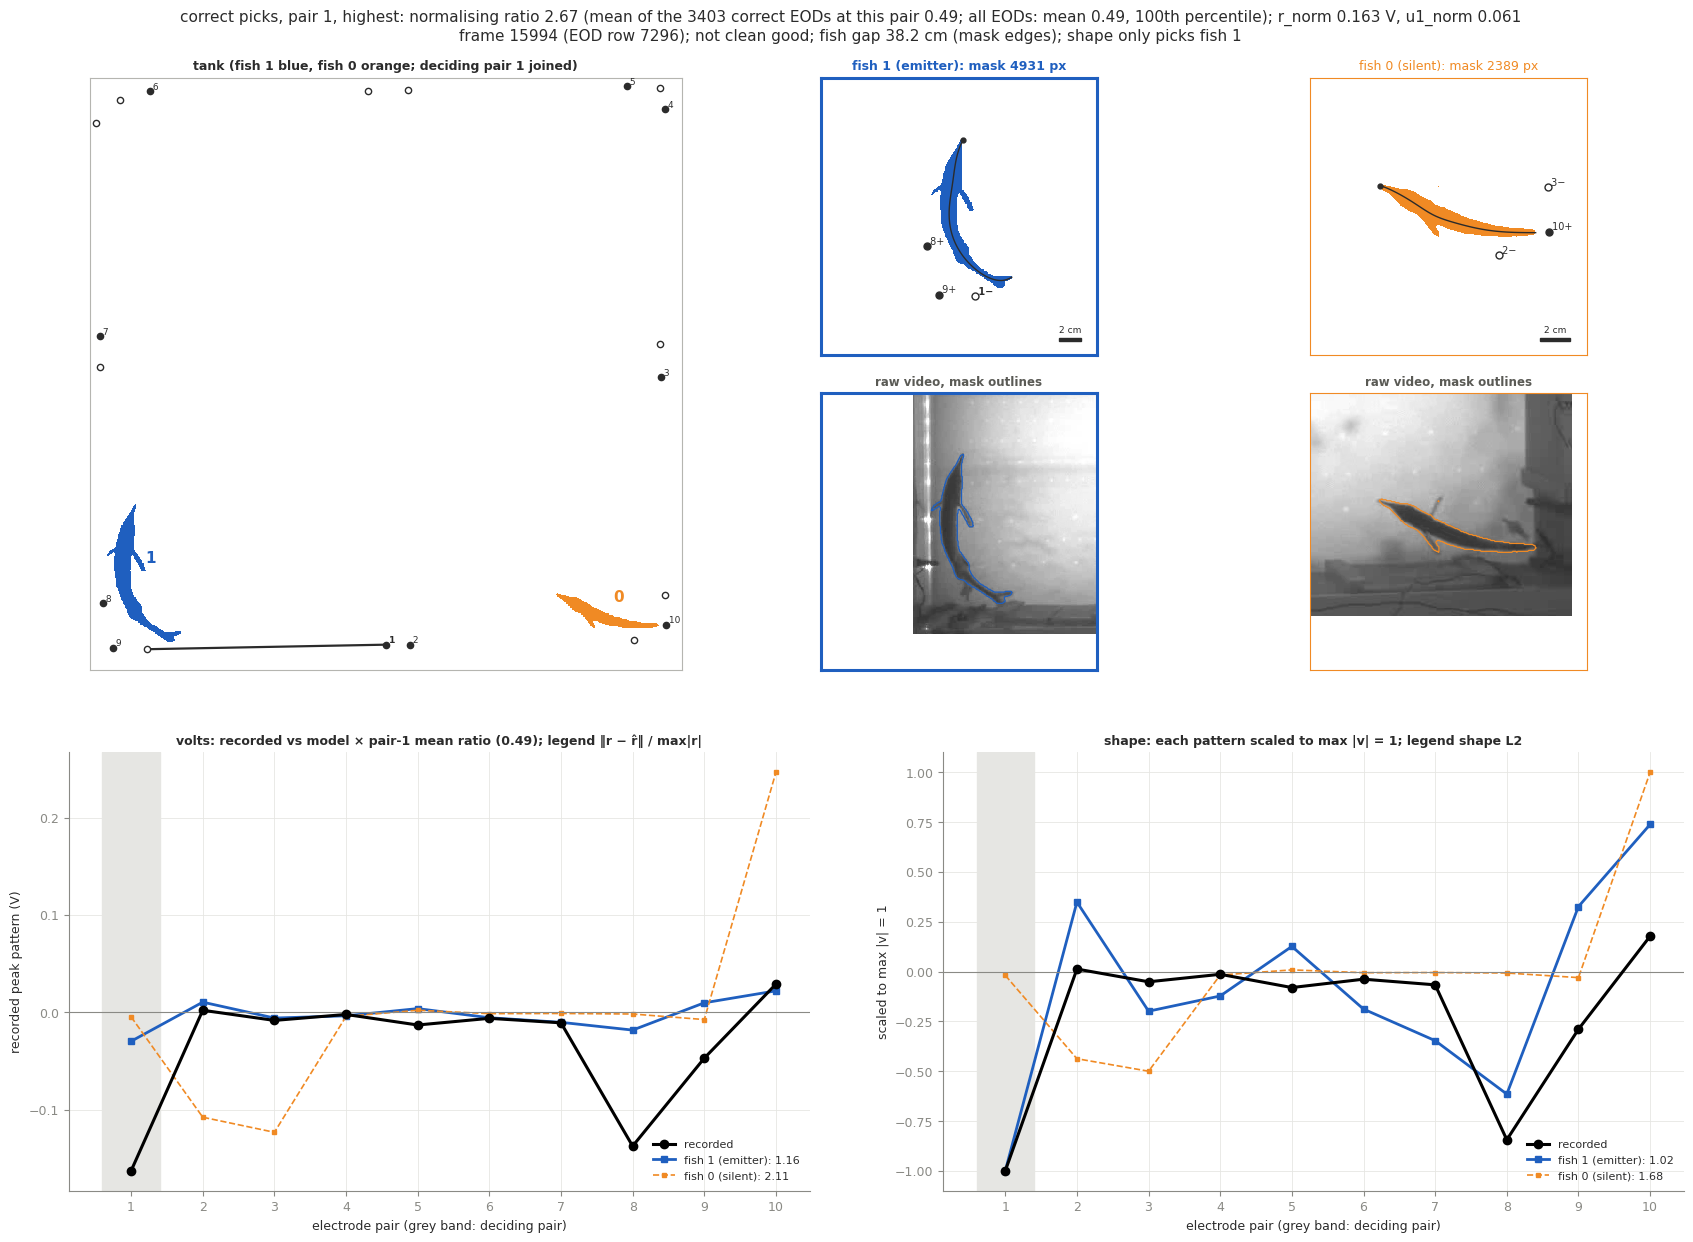

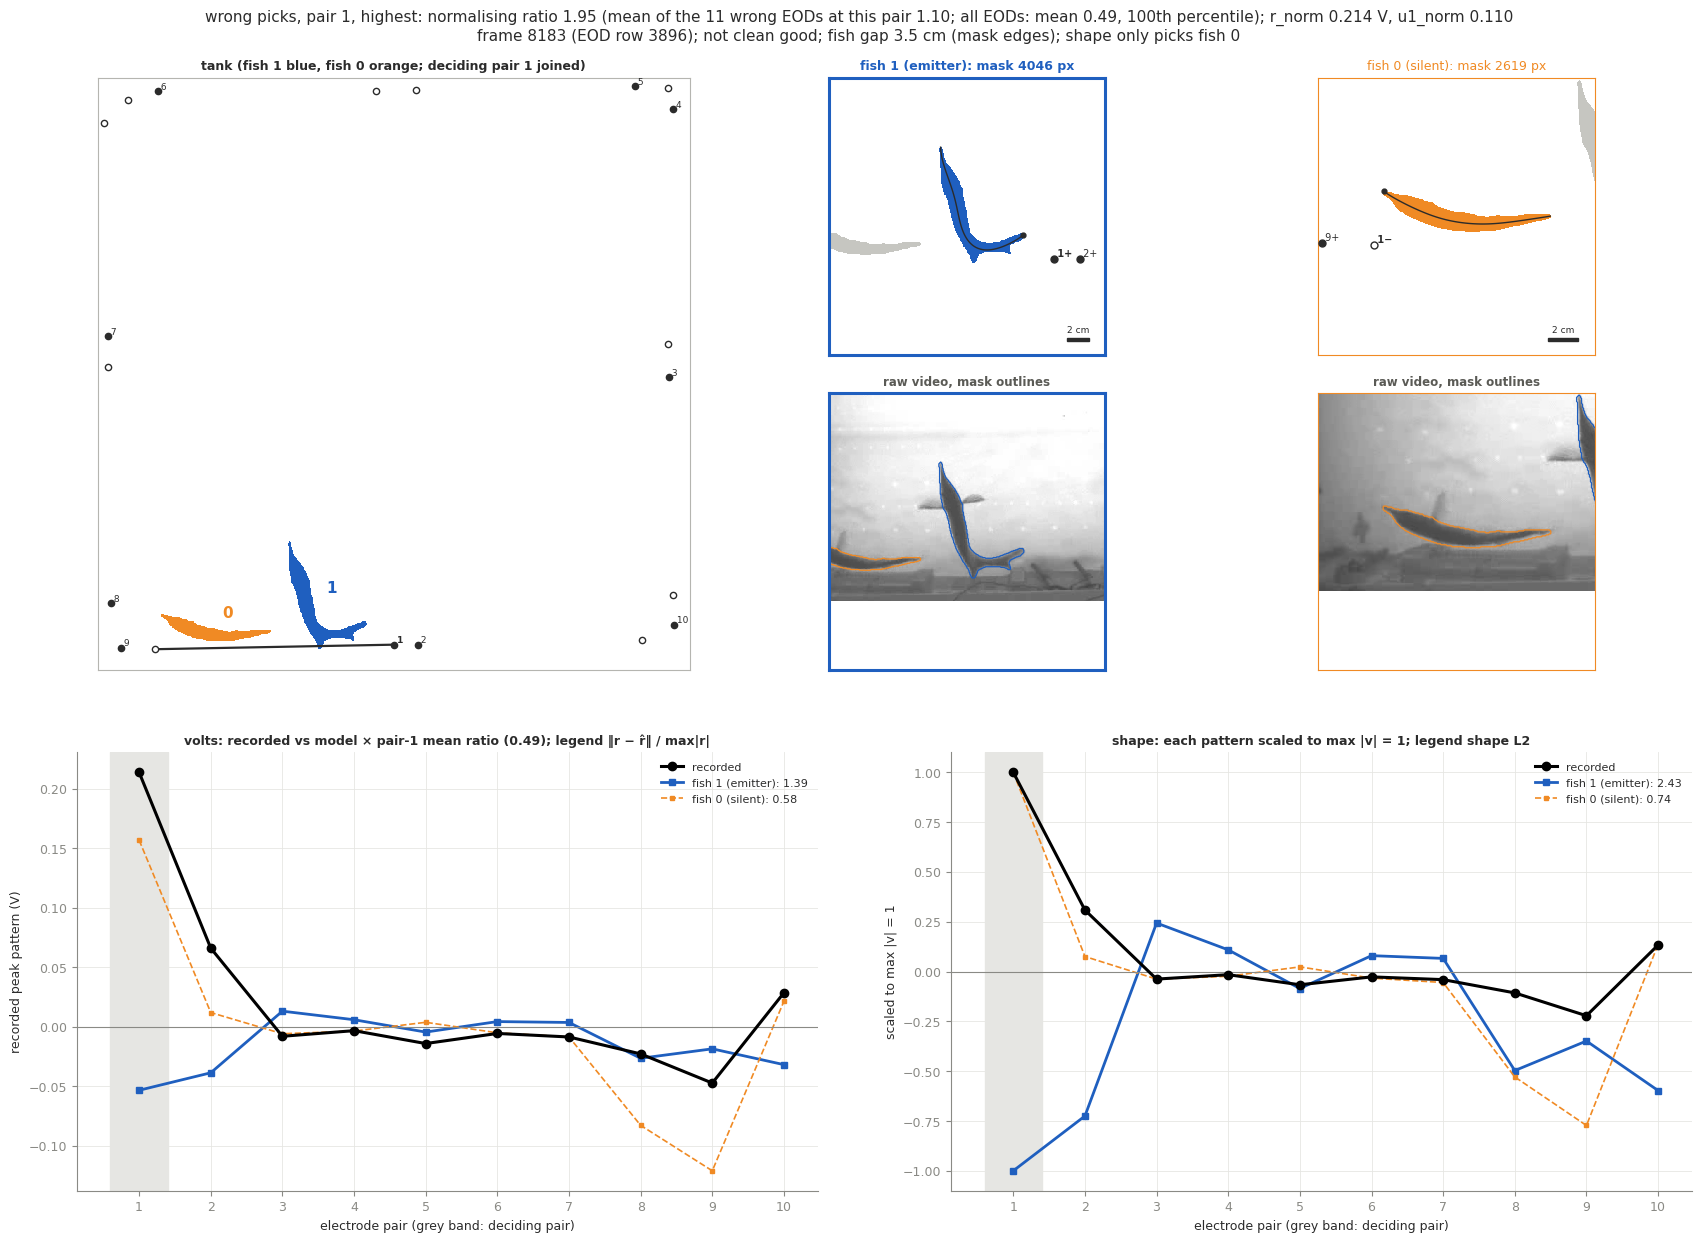

,set,pair,kind,ratio,pair_mean,set_mean,n_set,percentile,eod_row,Frame,clean good,correct,r_norm,u1_norm,u0_norm,gap_cm,mask_px_fish0,mask_px_fish1
0,correct,1,highest,2.671,0.488,0.486,3403,99.971,7296,15994,False,True,0.163,0.061,0.505,38.211,2389,4931
1,correct,1,highest,1.887,0.488,0.486,3403,99.824,7479,16604,False,True,0.134,0.071,0.280,0.066,2777,4662
2,correct,1,lowest,0.135,0.488,0.486,3403,0.000,8900,19594,False,True,0.056,0.413,0.106,0.066,2694,5748
3,correct,1,lowest,0.183,0.488,0.486,3403,0.029,8365,18330,False,True,0.048,0.263,0.368,49.759,2757,5505
4,correct,1,closest to mean,0.486,0.488,0.486,3403,71.412,17255,43277,True,True,0.215,0.442,0.422,39.490,2373,4095
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92,wrong,10,highest,1.079,0.643,0.614,13,89.696,6046,12853,False,False,0.050,0.046,0.118,0.066,4674,3024
93,wrong,10,highest,0.979,0.643,0.614,13,85.714,7655,16899,False,False,0.440,0.449,0.026,10.675,2627,5031
94,wrong,10,lowest,0.429,0.643,0.614,13,25.059,195,338,False,False,0.060,0.139,0.092,0.066,2633,4716
95,wrong,10,lowest,0.456,0.643,0.614,13,32.553,3374,6961,True,False,0.082,0.181,0.301,49.600,2274,4532


In [3]:
extra = {}
for set_ in SETS:
    with PdfPages(f'{OUT}/normalizing_ratio_examples_2fish_{set_}.pdf') as pdf:
        for n, (j, row) in enumerate(PK[PK.set == set_].iterrows()):
            fig, g, a0, a1 = figure(row); extra[j] = dict(gap_cm=g, mask_px_fish0=a0, mask_px_fish1=a1)
            name = f"{set_}_pair{int(row.pair):02d}_{row.kind.replace(' ', '_')}_frame{int(row.Frame)}.png"
            fig.savefig(f'{OUT}/per_eod_by_set/{name}', dpi=100, bbox_inches='tight'); pdf.savefig(fig, bbox_inches='tight')
            if n == 0: plt.show()
            else: plt.close(fig)
extra = pd.DataFrame.from_dict(extra, orient='index')
PK = PK.join(extra)
PK.to_csv(f'{OUT}/picked_eods.csv', index=False)
display(PK.drop(columns='i').round(3))

## Picked EODs side by side: what differs between high and low ratios

Per pair, the picked EODs' fish-1 mask size, the gap between the fish, and fish 1's position (midline centre) for the three kinds.

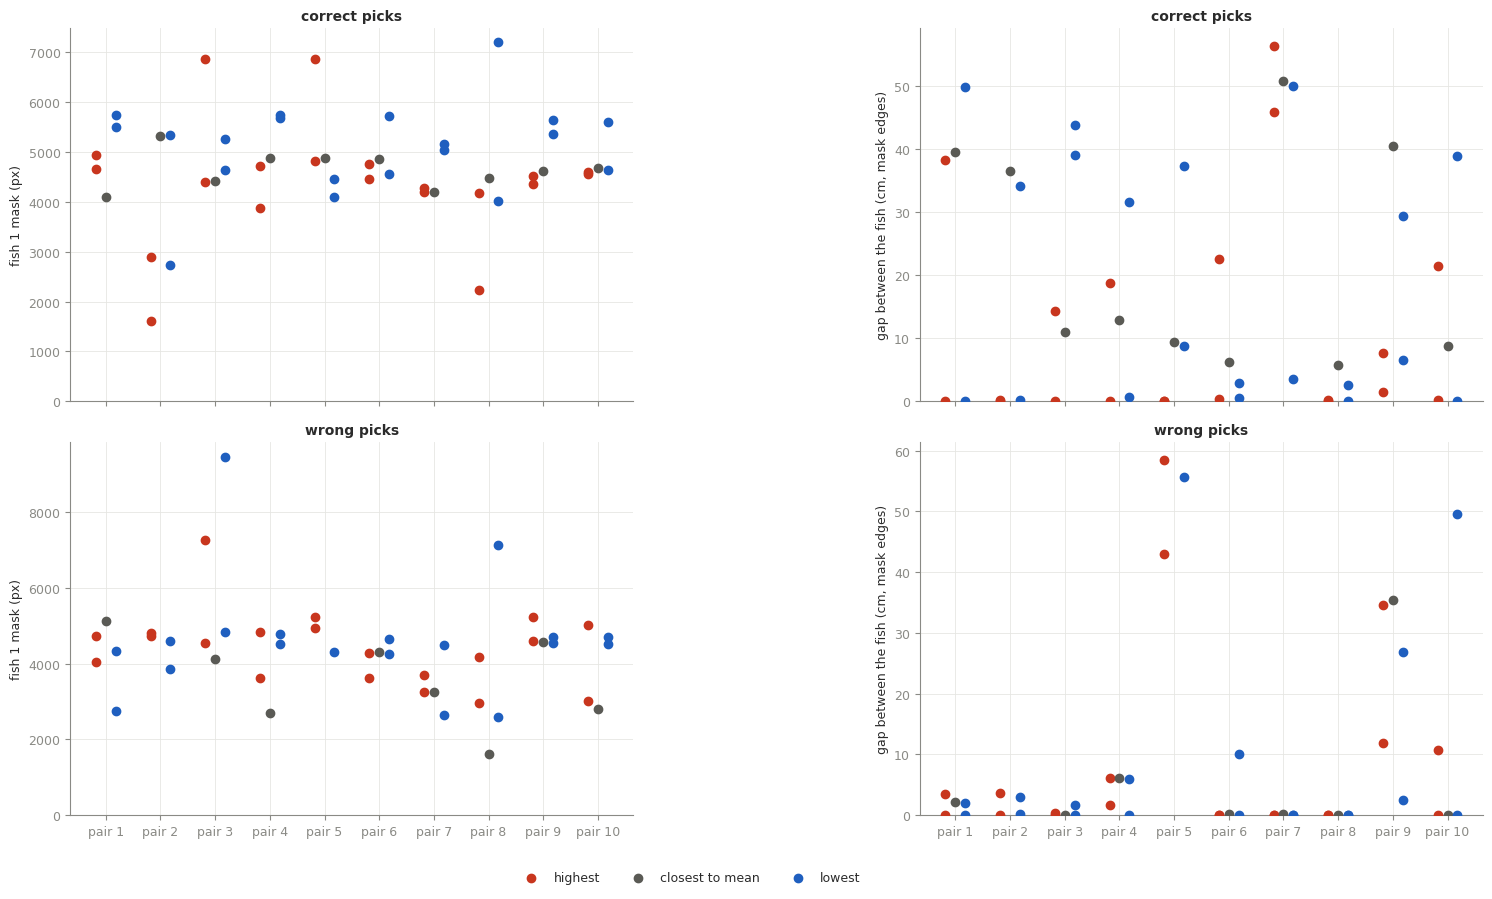

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
KCOL = {'highest': '#C8361E', 'closest to mean': '#5a5a55', 'lowest': '#1F5FBF'}
for r_, set_ in enumerate(SETS):
    for ax, col, yl in ((axs[r_, 0], 'mask_px_fish1', 'fish 1 mask (px)'), (axs[r_, 1], 'gap_cm', 'gap between the fish (cm, mask edges)')):
        for k_, (kind, c) in enumerate(KCOL.items()):
            s = PK[(PK.kind == kind) & (PK.set == set_)]; ax.scatter(s.pair + (k_ - 1) * 0.18, s[col], s=36, color=c, label=kind, zorder=3)
        ax.set(xticks=list(PAIRS), xticklabels=[f'pair {p}' for p in PAIRS], ylabel=yl, ylim=(0, None)); ax.set_title(f'{set_} picks', fontsize=10)
axs[1, 0].legend(frameon=False, loc='upper center', bbox_to_anchor=(1.1, -0.12), ncol=3)
plt.tight_layout(); fig.savefig(f'{OUT}/picked_eods_mask_and_gap.png', dpi=110, bbox_inches='tight'); plt.show()